# 📈 Sesiunea 4 - Regresie multiplă și polinomială

## Pregătire (rulează o dată)

In [24]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)
plt.rcParams["figure.figsize"] = (8, 4.5)

df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
df["Age"] = df["Age"].fillna(df["Age"].median())
df["SexNum"] = (df["Sex"] == "male").astype(int)

FEATURES = ["Pclass", "Age", "SibSp", "Parch", "SexNum"]
X = df[FEATURES]; y = df["Fare"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print("gata:", X_train.shape[0], "train /", X_test.shape[0], "test")

gata: 712 train / 179 test


## 1 · Regresie multiplă 🔧

Trecem de la o variabilă la mai multe. Fiecare variabilă are propria pantă (coeficient).

**Exercițiul 1.1** - Compară regresia simplă (doar `Pclass`) cu cea multiplă (toate features-urile). Cât crește R²? Și ce spune fiecare coeficient?

In [25]:
simple = # ...
multi  = # ...

print(f"R2 simplă (Pclass):  {simple.score(X_test[['Pclass']], y_test):.3f}")
print(f"R2 multiplă (toate): {multi.score(X_test, y_test):.3f}")
print("\nCoeficienți (efectul fiecărei variabile):")
print(pd.Series(multi.coef_, index=FEATURES).round(2))

R2 simplă (Pclass):  0.370
R2 multiplă (toate): 0.462

Coeficienți (efectul fiecărei variabile):
Pclass   -33.39
Age       -0.13
SibSp      5.20
Parch      9.68
SexNum    -3.94
dtype: float64


Cu mai multe variabile nu mai putem desena o dreaptă pe hârtie (sunt 5 dimensiuni). În loc de asta, ne uităm la **prezis vs real**: cât de aproape sunt punctele de diagonală?

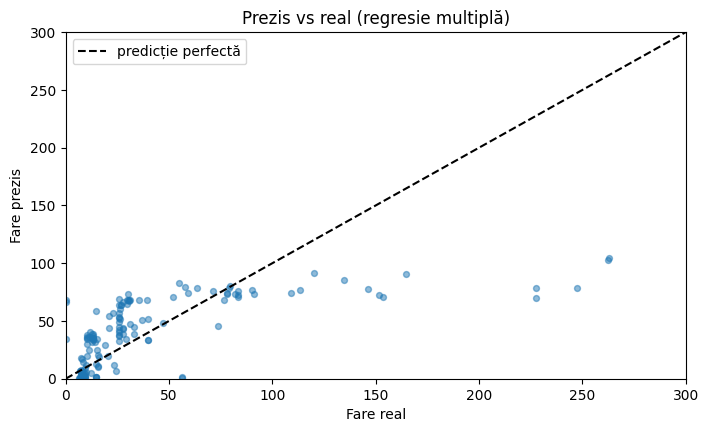

In [26]:
pred = multi.predict(X_test)

plt.scatter(y_test, pred, s=18, alpha=0.5)
plt.plot([0,300],[0,300], "k--", label="predicție perfectă")
plt.xlabel("Fare real"); plt.ylabel("Fare prezis"); plt.xlim(0,300); plt.ylim(0,300)
plt.legend(); plt.title("Prezis vs real (regresie multiplă)"); plt.show()

**Exercițiul 1.2 (de gândit)** - Ce features e cel mai bine să alegem? Rulează comparația de mai jos. Merită să adăugăm chiar toate variabilele?

<details>
<summary><b>💡 Răspuns (deschide după ce ai ghicit)</b></summary>
<br>
Nu neapărat „toate". Vrei variabilele **informative** și eviți zgomotul. Aici, `Pclass` cară cea mai mare parte; `Age` aproape că nu ajută la preț. Un set bun e adesea mai mic și mai curat decât „tot". Regula: adaugă o variabilă doar dacă îmbunătățește scorul pe **test**.
</details>

In [27]:
subsets = {
    "doar Pclass":            ["Pclass"],
    "Pclass + SexNum":        ["Pclass", "SexNum"],
    "Pclass + Age":           ["Pclass", "Age"],
    "toate":                  FEATURES,
    "toate fără Age":         ["Pclass", "SibSp", "Parch", "SexNum"],
}
for name, cols in subsets.items():
    m = LinearRegression().fit(X_train[cols], y_train)
    print(f"{name:22s} -> R2 test = {m.score(X_test[cols], y_test):.3f}")

doar Pclass            -> R2 test = 0.370
Pclass + SexNum        -> R2 test = 0.395
Pclass + Age           -> R2 test = 0.386
toate                  -> R2 test = 0.462
toate fără Age         -> R2 test = 0.461


## 2 · Standardizarea datelor (StandardScaler) ⚖️
*(după slide-ul „Standardizare")*

Aducem toate variabilele la aceeași scală: medie 0, deviație 1. `z = (x - medie) / deviație`.

**Exercițiul 2.1** - Uită-te la scalele variabilelor înainte, apoi după `StandardScaler`.

In [36]:
print("ÎNAINTE (scale foarte diferite):")
print(X_train.describe().loc[["mean", "std"]].round(2))

scaler = StandardScaler().fit(X_train)          # învață media/deviația DOAR din train
X_train_scaled = scaler.transform(X_train)

print("\nDUPĂ standardizare (medie ~0, deviație ~1):")
print(pd.DataFrame(X_train_scaled, columns=FEATURES).describe().loc[["mean", "std"]].round(2))

ÎNAINTE (scale foarte diferite):
      Pclass    Age  SibSp  Parch  SexNum
mean    2.32  29.40   0.53   0.39    0.65
std     0.83  13.11   1.14   0.82    0.48

DUPĂ standardizare (medie ~0, deviație ~1):
      Pclass  Age  SibSp  Parch  SexNum
mean    -0.0  0.0    0.0    0.0     0.0
std      1.0  1.0    1.0    1.0     1.0


## 3 · Multiplă vs Polinomială 📐
*(după slide-ul „Multiplă vs Polinomială")*

Multiplă = mai multe variabile, drepte. Polinomială = aceleași variabile, dar cu **puteri și interacțiuni** (curbe). `PolynomialFeatures` le creează automat.

**Exercițiul 3.1** - Compară gradul 1 (multiplă) cu gradul 2 (polinomială). Prind curbele ceva în plus?

In [37]:
for deg in [1, 2]:
    pipe = make_pipeline(StandardScaler(),
                         PolynomialFeatures(deg),
                         LinearRegression())
    pipe.fit(X_train, y_train)
    tip = "multiplă (drept)" if deg == 1 else "polinomială (curbe)"
    print(f"grad {deg} - {tip:18s}: R2 test = {pipe.score(X_test, y_test):.3f}")

grad 1 - multiplă (drept)  : R2 test = 0.462
grad 2 - polinomială (curbe): R2 test = 0.668


## 4 · Metrici de regresie 📊
*(după slide-urile „Metrici")*

O singură cifră nu spune tot. Calculăm mai multe și vedem ce ne spune fiecare.

**Exercițiul 4.1** - Calculează MAE, RMSE și R² pentru modelul multiplu.

In [31]:
pred = LinearRegression().fit(X_train, y_train).predict(X_test)
print(f"MAE  = {mean_absolute_error(y_test, pred):.2f} lire   (greșeala medie)")
print(f"RMSE = {mean_squared_error(y_test, pred)**0.5:.2f} lire   (penalizează erorile mari)")
print(f"R2   = {r2_score(y_test, pred):.3f}")

MAE  = 20.57 lire   (greșeala medie)
RMSE = 35.10 lire   (penalizează erorile mari)
R2   = 0.462


**Exercițiul 4.2 (de gândit)** - Observă că RMSE e mult mai mare decât MAE. De ce? Și ce metrică ai alege pentru `Fare`?

<details>
<summary><b>💡 Răspuns (deschide după ce ai ghicit)</b></summary>
<br>
**RMSE >> MAE** înseamnă că avem câteva greșeli mari (biletele foarte scumpe, 512£, pe care modelul le ratează). Pentru `Fare`, **MAE** e cea mai onestă și ușor de explicat („în medie greșim cu ~X lire"); R² pentru comparat modele.
</details>

## 5 · Underfitting vs Overfitting ⚖️
*(după slide-ul „Underfitting vs Overfitting")*

Prea simplu = underfit (slab peste tot). Prea complex = overfit (grozav pe train, slab pe test). Hai să-l vedem, ușor, pe datele noastre.

**Exercițiul 5.1**

In [32]:
for deg in [1, 2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression())
    pipe.fit(X_train, y_train)
    print(f"grad {deg}:  train {pipe.score(X_train, y_train):.3f}   test {pipe.score(X_test, y_test):.3f}")

grad 1:  train 0.351   test 0.462
grad 2:  train 0.459   test 0.668
grad 3:  train 0.509   test 0.643
grad 4:  train 0.560   test 0.581


**Ce vezi:** pe train scorul urcă mereu; pe test crește la început, apoi **cade** (la grad 4 se prăbușește). Acolo e overfitting. Vrem gradul din vârf.

## 6 · Cum combatem overfitting-ul (Ridge) 🛡️
*(după slide-urile „Regularizare / Ridge vs Lasso")*

Regularizarea penalizează coeficienții mari, ca modelul să rămână stabil. `alpha` = cât de tare penalizăm.

**Exercițiul 6.1** - Ia gradul 3 (care făcea overfitting) și adaugă Ridge cu `alpha` crescând. Se repară testul?

In [33]:
for alpha in [0, 1, 10, 100]:
    model = Ridge(alpha=alpha) if alpha > 0 else LinearRegression()
    pipe = make_pipeline(StandardScaler(), PolynomialFeatures(3, include_bias=False), model)
    pipe.fit(X_train, y_train)
    print(f"alpha {alpha:>4}:  train {pipe.score(X_train, y_train):.3f}   test {pipe.score(X_test, y_test):.3f}")

alpha    0:  train 0.509   test 0.643
alpha    1:  train 0.509   test 0.645
alpha   10:  train 0.508   test 0.659
alpha  100:  train 0.499   test 0.690


## 7 · GridSearchCV: încercăm mai multe variante 🔍
*(după slide-ul „GridSearchCV")*

Nu ghicim manual `grad` și `alpha`. Le încercăm pe toate, cu cross-validation, și lăsăm căutarea să aleagă.

**Exercițiul 7.1** - Caută cea mai bună combinație `grad` × `alpha`.

In [34]:
pipe = make_pipeline(StandardScaler(), PolynomialFeatures(include_bias=False), Ridge())
grid = {"polynomialfeatures__degree": [1, 2, 3], "ridge__alpha": [0.1, 1, 10, 100]}
gs = GridSearchCV(pipe, grid, cv=5, scoring="r2").fit(X_train, y_train)

print("cea mai bună configurație:", gs.best_params_)
print(f"R2 pe test = {gs.best_estimator_.score(X_test, y_test):.3f}")

cea mai bună configurație: {'polynomialfeatures__degree': 3, 'ridge__alpha': 100}
R2 pe test = 0.690


## Recap 🎓

Am parcurs, concept cu concept: **regresie multiplă** → **standardizare** → **multiplă vs polinomială** → **metrici** → **underfitting/overfitting** → **regularizare** → **GridSearchCV**.

Pe scurt: pornim de la o dreaptă, adăugăm variabile și curbe, apoi ținem complexitatea în frâu ca să generalizeze bine.

